In [1]:
# Cell 1: Import and load clean data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Load clean merged dataset from notebook 02
df = pd.read_csv('../data/processed/merged_clean.csv', index_col=0, parse_dates=True)

# Set a style for all charts
plt.style.use('seaborn-v0_8-whitegrid')

print("Data loaded :)")
print(f"Shape: {df.shape}")
print(f"Date range: {df.index[0].date()} to {df.index[-1].date()}")

Data loaded :)
Shape: (302, 13)
Date range: 2001-04-01 to 2026-05-01


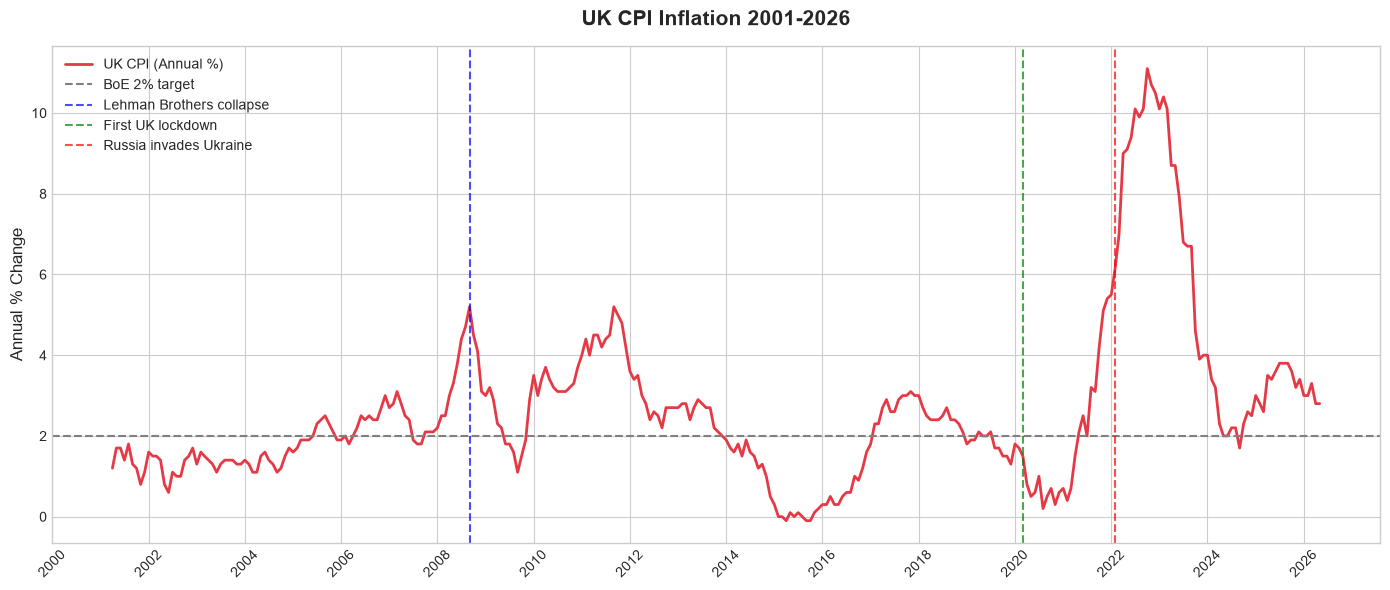

Chart 1 saved :)


In [2]:
# Cell 2: Create chart 1 - UK CPI inflation over time
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(df.index, df['cpi'], color='#E63946', linewidth=2, label='UK CPI (Annual %)')
ax.axhline(y=2, color='grey', linestyle='--', linewidth=1.5, label='BoE 2% target')

# Add vertical lines for specific dates of interest
events = {
    '2008-09-01': ('Lehman Brothers collapse', 'blue'),
    '2020-03-01': ('First UK lockdown', 'green'),
    '2022-02-01': ('Russia invades Ukraine', 'red'),
}

for date, (label, color) in events.items():
    ax.axvline(x=pd.Timestamp(date), color=color, linestyle='--', 
               linewidth=1.5, alpha=0.7, label=label)

ax.set_title('UK CPI Inflation 2001-2026', fontsize=15, fontweight='bold', pad=15)
ax.set_ylabel('Annual % Change', fontsize=12)
ax.legend(loc='upper left', fontsize=10)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('../outputs/charts/01_cpi_history.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart 1 saved :)")

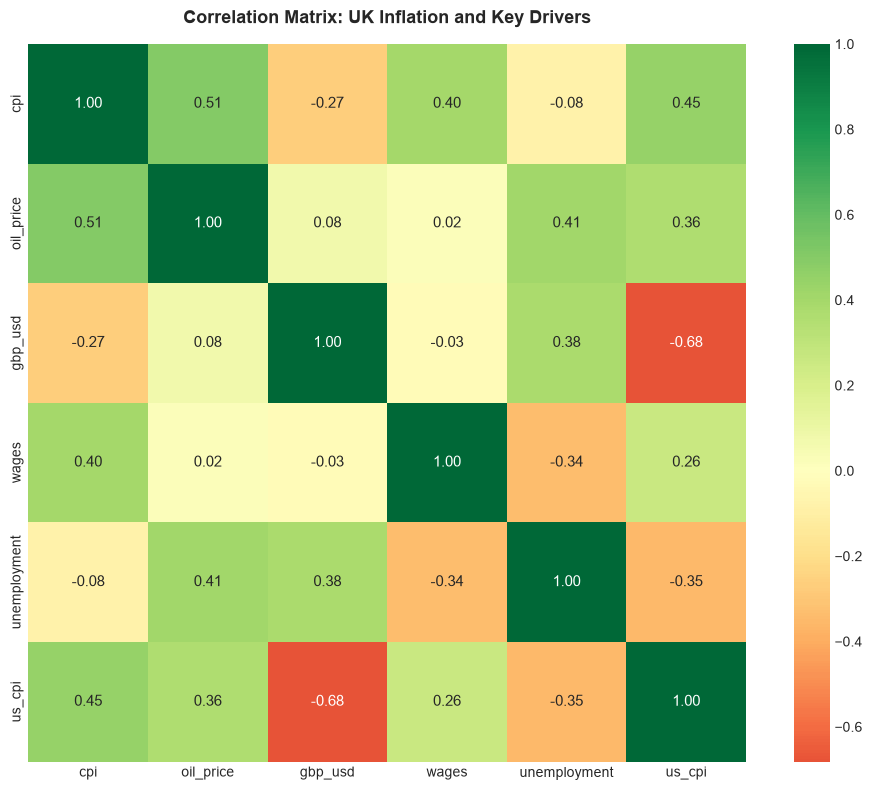

Chart 2 saved :)


In [3]:
# Cell 3: Create chart 2 - Correlation heatmap
fig, ax = plt.subplots(figsize=(10, 8))

# Only select the main economic variables (not the lags for now)
corr_cols = ['cpi', 'oil_price', 'gbp_usd', 'wages', 'unemployment', 'us_cpi']

# Calculate correlation matrix
# Correlation ranges from -1 (perfect opposite) to +1 (perfect together)
# 0 means no relationship
corr_matrix = df[corr_cols].corr()

sns.heatmap(corr_matrix,
            annot=True,        # show numbers inside each cell
            fmt='.2f',         # round to 2 decimal places
            cmap='RdYlGn',     # red=negative, yellow=neutral, green=positive
            center=0,
            square=True,
            ax=ax,
            annot_kws={'size': 11})

ax.set_title('Correlation Matrix: UK Inflation and Key Drivers',
             fontsize=13, fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig('../outputs/charts/02_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart 2 saved :)")

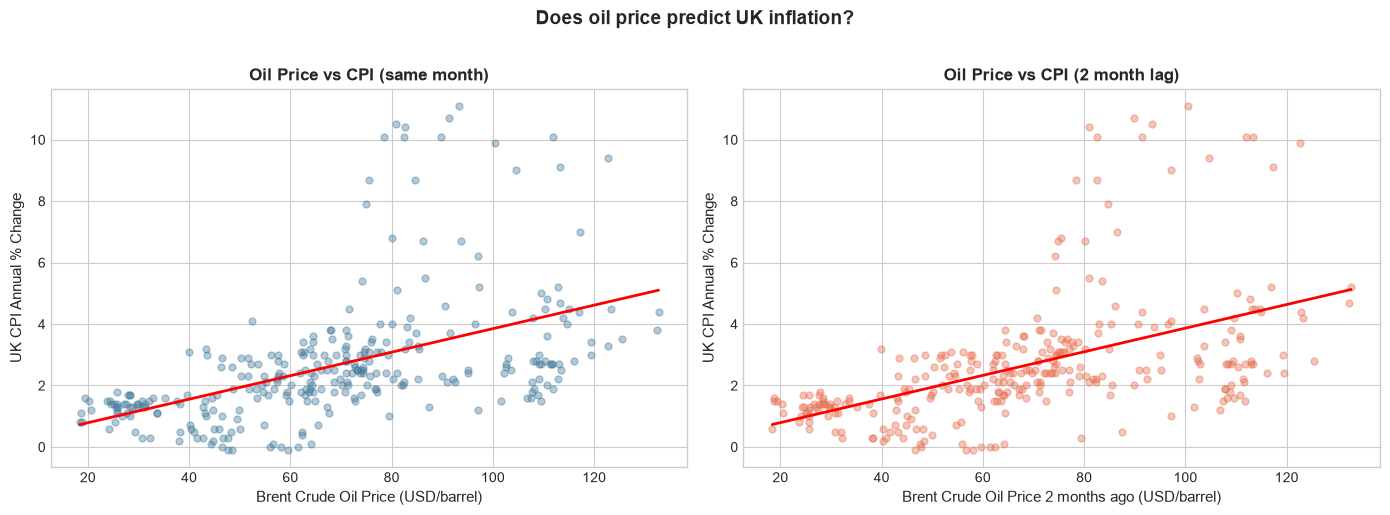

Chart 3 saved :)


In [4]:
# Cell 4: Create chart 3 - Oil price vs CPI (scatter plot)
# Visualises the correlation between oil prices and inflation

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: contemporaneous (same month)
ax1 = axes[0]
ax1.scatter(df['oil_price'], df['cpi'], alpha=0.4, color='#457B9D', s=25)

# Add trend line
z = np.polyfit(df['oil_price'], df['cpi'], 1)
p = np.poly1d(z)
x_line = np.linspace(df['oil_price'].min(), df['oil_price'].max(), 100)
ax1.plot(x_line, p(x_line), color='red', linewidth=2)

ax1.set_xlabel('Brent Crude Oil Price (USD/barrel)', fontsize=11)
ax1.set_ylabel('UK CPI Annual % Change', fontsize=11)
ax1.set_title('Oil Price vs CPI (same month)', fontsize=12, fontweight='bold')

# Right plot: with 2 month lag
ax2 = axes[1]
ax2.scatter(df['oil_lag2'], df['cpi'], alpha=0.4, color='#E76F51', s=25)

z2 = np.polyfit(df['oil_lag2'], df['cpi'], 1)
p2 = np.poly1d(z2)
x_line2 = np.linspace(df['oil_lag2'].min(), df['oil_lag2'].max(), 100)
ax2.plot(x_line2, p2(x_line2), color='red', linewidth=2)

ax2.set_xlabel('Brent Crude Oil Price 2 months ago (USD/barrel)', fontsize=11)
ax2.set_ylabel('UK CPI Annual % Change', fontsize=11)
ax2.set_title('Oil Price vs CPI (2 month lag)', fontsize=12, fontweight='bold')

plt.suptitle('Does oil price predict UK inflation?', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../outputs/charts/03_oil_vs_cpi.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart 3 saved :)")

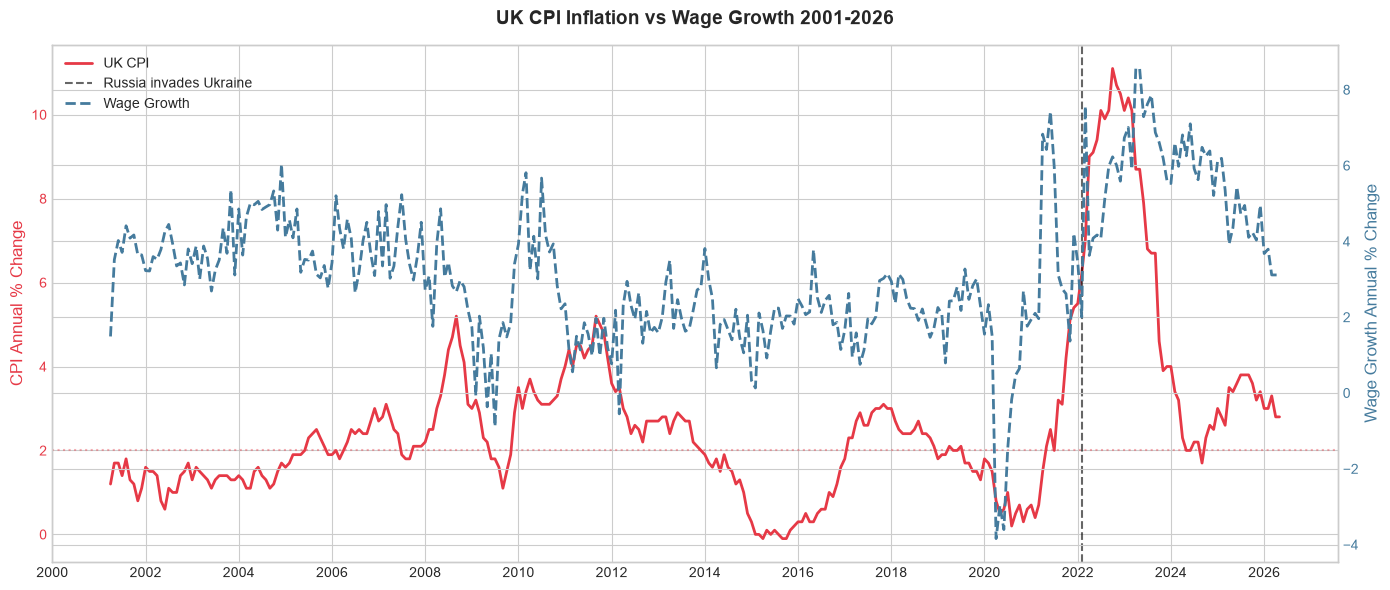

Chart 4 saved :)


In [5]:
# Cell 5: Create chart 4 - Wages and CPI over time (dual axis chart)
# Plots two variables with different scales on the same chart

fig, ax1 = plt.subplots(figsize=(14, 6))

# Plot CPI on left axis
ax1.plot(df.index, df['cpi'], color='#E63946', linewidth=2, label='UK CPI')
ax1.set_ylabel('CPI Annual % Change', color='#E63946', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#E63946')
ax1.axhline(y=2, color='#E63946', linestyle=':', alpha=0.4)

# Create second y axis for wages
ax2 = ax1.twinx()
ax2.plot(df.index, df['wages'], color='#457B9D', linewidth=2, 
         linestyle='--', label='Wage Growth')
ax2.set_ylabel('Wage Growth Annual % Change', color='#457B9D', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#457B9D')

# Add event lines
ax1.axvline(x=pd.Timestamp('2022-02-01'), color='black', 
            linestyle='--', linewidth=1.5, alpha=0.6, label='Russia invades Ukraine')

# Combined legend from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=10)

ax1.set_title('UK CPI Inflation vs Wage Growth 2001-2026', 
              fontsize=14, fontweight='bold', pad=15)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('../outputs/charts/04_wages_vs_cpi.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart 4 saved :)")

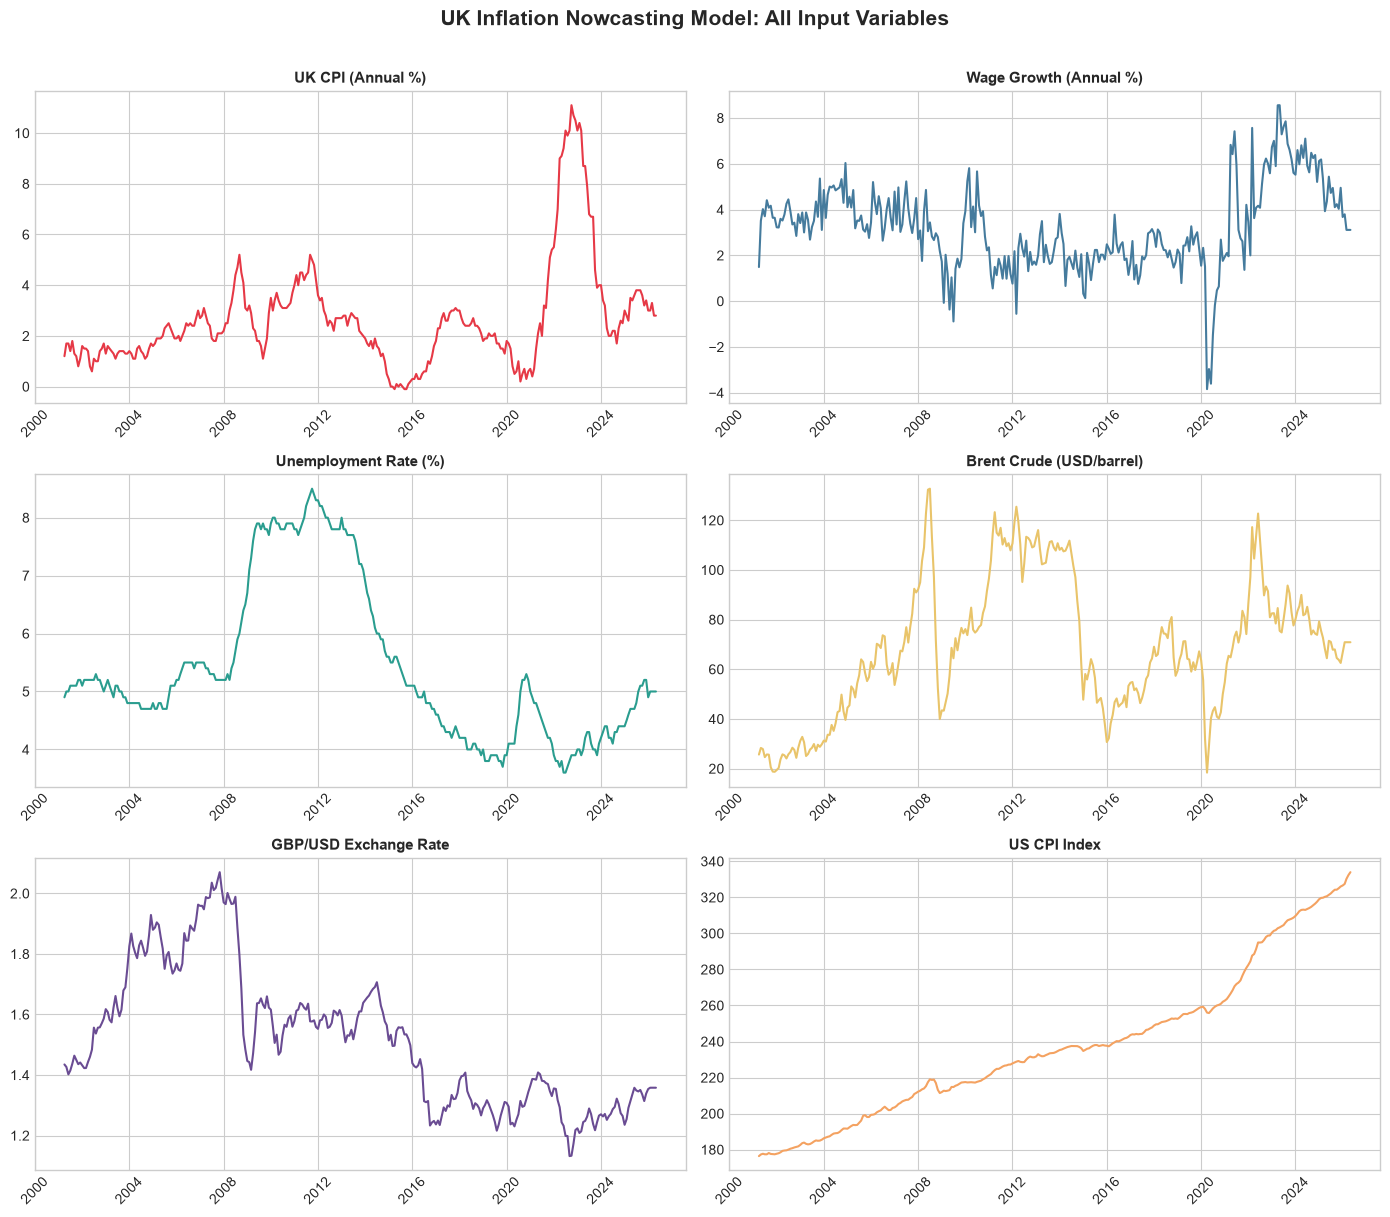

Chart 5 saved :)


In [6]:
# Cell 6: Create chart 5 - All variables over time in one dashboard plot to give overview of all data

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
fig.suptitle('UK Inflation Nowcasting Model: All Input Variables', 
             fontsize=15, fontweight='bold', y=1.01)

# Define what to plot in each panel
plots = [
    ('cpi',          'UK CPI (Annual %)',        '#E63946'),
    ('wages',        'Wage Growth (Annual %)',    '#457B9D'),
    ('unemployment', 'Unemployment Rate (%)',     '#2A9D8F'),
    ('oil_price',    'Brent Crude (USD/barrel)',  '#E9C46A'),
    ('gbp_usd',      'GBP/USD Exchange Rate',     '#6A4C93'),
    ('us_cpi',       'US CPI Index',              '#F4A261'),
]

for ax, (col, title, color) in zip(axes.flatten(), plots):
    ax.plot(df.index, df[col], color=color, linewidth=1.5)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.xaxis.set_major_locator(mdates.YearLocator(4))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.savefig('../outputs/charts/05_all_variables.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart 5 saved :)")